# Credit Default Prediction: The Cost of Explainability in Consumer Credit Risk

**Course:** COS802, MIT Big Data Science, University of Pretoria  
**Author:** <Name>, <Student number>  
**Notebook:** 01 Exploratory data analysis

## Purpose
This notebook explores the Home Credit Default Risk data before any modelling. It assesses data quality across all seven tables, investigates anomalies, examines the target imbalance and key drivers of default, and records the cleaning and feature decisions carried forward to notebook 02.

## Project research questions
- **RQ1** How much do bureau and repayment history tables improve default prediction over application data alone?
- **RQ2** How much predictive performance is lost when an inherently interpretable model (EBM) is used instead of LightGBM?

## Data
Home Credit Default Risk (Kaggle, `home-credit-default-risk`): 307,511 labelled applicants in `application_train`, of which 24,825 defaulted (8.07%). The main application table is supported by six related tables covering bureau history, previous applications and repayment behaviour. `application_test` is excluded, as it has no target labels.

## Notebook outline
### 1. Setup
    1.1 Imports and configuration
    1.2 Load data

### 2. Data Quality
    2.1 DQ check function
    2.2 DQ checks per table
    2.3 DQ summary

### 3. Investigate Issues
    3.1 DAYS_EMPLOYED anomaly
    3.2 Placeholder categories (XNA / XAP)
    3.3 Installment duplicates
    3.4 Applicant coverage across tables

### 4. Target
    4.1 Class imbalance

### 5. Key Features vs Default
    5.1 Age
    5.2 External source scores
    5.3 Correlations with target
    5.4 Education and income type

### 6. Supporting Tables
    6.1 Table relationships
    6.2 Records per applicant

### 7. Summary
    7.1 Key findings
    7.2 Actions for notebook 02

### 8. Save
    8.1 Convert to parquet

####

### 1. Setup

1.1 Importing of data

In [1]:
#Importing relevant packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

seed = 27 

pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

1.2 Loading of data

In [2]:
directory = Path(r"C:\Users\mekay\Downloads\COS802 Data")
seed = 27

app_train       = pd.read_csv(directory / "application_train.csv")
bureau          = pd.read_csv(directory/ "bureau.csv")
bureau_balance  = pd.read_csv(directory/ "bureau_balance.csv")
prev_app        = pd.read_csv(directory/ "previous_application.csv")
pos_cash        = pd.read_csv(directory/ "POS_CASH_balance.csv")
credit_card     = pd.read_csv(directory/ "credit_card_balance.csv")
installments    = pd.read_csv(directory/ "installments_payments.csv")

# 

### 2. Data Quality

2.1 DQ Function

In [3]:
### Due to the number of tables, it will be easier to create DQ check function which we will run over all 7 tables

def dq_check(df, df_name, primary_key):
    if isinstance(primary_key, str):
        primary_key = [primary_key]

    print(f"=== {df_name} ===")
    print(f"Shape: {df.shape}")

    # Primary key fields should have no duplicates or missing values
    print(f"Duplicate keys: {df.duplicated(subset=primary_key).sum()}")
    print(f"Missing keys: {df[primary_key].isna().any(axis=1).sum()}")

    print("=================\n")

2.2 DQ checks per table

In [4]:
dq_check(app_train, "training data", primary_key="SK_ID_CURR")
dq_check(bureau, "bureau data", primary_key="SK_ID_BUREAU")
dq_check(bureau_balance, "bureau balance data", primary_key=["SK_ID_BUREAU", "MONTHS_BALANCE"])
dq_check(prev_app, "previous applications data", primary_key="SK_ID_PREV")
dq_check(pos_cash, "POS cash data", primary_key=["SK_ID_PREV", "MONTHS_BALANCE"])
dq_check(credit_card, "credit card data", primary_key=["SK_ID_PREV", "MONTHS_BALANCE"])
dq_check(installments, "installments data", primary_key=["SK_ID_PREV", "NUM_INSTALMENT_NUMBER", "NUM_INSTALMENT_VERSION"])

=== training data ===
Shape: (307511, 122)
Duplicate keys: 0
Missing keys: 0

=== bureau data ===
Shape: (1716428, 17)
Duplicate keys: 0
Missing keys: 0

=== bureau balance data ===
Shape: (27299925, 3)
Duplicate keys: 0
Missing keys: 0

=== previous applications data ===
Shape: (1670214, 37)
Duplicate keys: 0
Missing keys: 0

=== POS cash data ===
Shape: (10001358, 8)
Duplicate keys: 0
Missing keys: 0

=== credit card data ===
Shape: (3840312, 23)
Duplicate keys: 0
Missing keys: 0

=== installments data ===
Shape: (13605401, 8)
Duplicate keys: 653483
Missing keys: 0



### 2.3 DQ Summary

All seven tables have complete primary keys, with no missing values in any key field. Six of the seven tables also have no duplicate keys. The exception is `installments`, where 653,483 rows share a key (`SK_ID_PREV`, `NUM_INSTALMENT_NUMBER`, `NUM_INSTALMENT_VERSION`) with another row. A likely explanation is that a single instalment can be paid across several transactions. This is investigated in section 3.3.

# 

### 3. Investigate Issues


The checks in section 2 confirmed that the table structures are sound. This section looks at the values within individual fields and reviews numeric ranges and categorical values to identify anomalies, placeholder codes and inconsistencies. It also examines the duplicate keys found in `installments`, and how many applicants have records in each supporting table.

# 

3.1) Numerical issues

In [5]:
app_train.describe().T

,count,mean,std,min,25%,50%,75%,max
SK_ID_CURR,"307,511.00","278,180.52","102,790.18","100,002.00","189,145.50","278,202.00","367,142.50","456,255.00"
TARGET,"307,511.00",0.08,0.27,0.00,0.00,0.00,0.00,1.00
CNT_CHILDREN,"307,511.00",0.42,0.72,0.00,0.00,0.00,1.00,19.00
AMT_INCOME_TOTAL,"307,511.00","168,797.92","237,123.15","25,650.00","112,500.00","147,150.00","202,500.00","117,000,000.00"
AMT_CREDIT,"307,511.00","599,026.00","402,490.78","45,000.00","270,000.00","513,531.00","808,650.00","4,050,000.00"
AMT_ANNUITY,"307,499.00","27,108.57","14,493.74","1,615.50","16,524.00","24,903.00","34,596.00","258,025.50"
AMT_GOODS_PRICE,"307,233.00","538,396.21","369,446.46","40,500.00","238,500.00","450,000.00","679,500.00","4,050,000.00"
REGION_POPULATION_RELATIVE,"307,511.00",0.02,0.01,0.00,0.01,0.02,0.03,0.07
DAYS_BIRTH,"307,511.00","-16,037.00","4,363.99","-25,229.00","-19,682.00","-15,750.00","-12,413.00","-7,489.00"
DAYS_EMPLOYED,"307,511.00","63,815.05","141,275.77","-17,912.00","-2,760.00","-1,213.00",-289.00,"365,243.00"


**App_train numerical anomalies**

**`DAYS_EMPLOYED`** has a maximum of 365,243 days (roughly 1,000 years) which is not a plausible employment length and appears to be a placeholder code.

**`AMT_INCOME_TOTAL`** has a maximum of 117 million against a 75th percentile of 202,500 which suggests a small number of extreme values.

**`AMT_REQ_CREDIT_BUREAU_QRT`**, which tracks the number of Credit Bureau enquiries 3 months before the application has a maximum of 261 enquirie or roughly more than 2 checks a day, so this value is likely a recording error.

**`OBS_30_CNT_SOCIAL_CIRCLE` and `OBS_60_CNT_SOCIAL_CIRCLE`** reach roughly 348 and 344 respectively, against a 75th percentile of 2. These are extreme outliers.

**`OWN_CAR_AGE`** has a maximum of 91 years which isn't plausible. 

**`CNT_CHILDREN` and `CNT_FAM_MEMBERS`** reach 19 and 20 which is not impossible but very rare

**FLAG_ fields:** `FLAG_DOCUMENT_2`, `4`, `7`, `10`, `12`, `17`, `19`, `20` and `21` aer binary fields with most entries having the same values. Because they barely vary, they won’t help the model tell defaulters apart.

#

In [6]:
bureau.describe().T

,count,mean,std,min,25%,50%,75%,max
SK_ID_CURR,"1,716,428.00","278,214.93","102,938.56","100,001.00","188,866.75","278,055.00","367,426.00","456,255.00"
SK_ID_BUREAU,"1,716,428.00","5,924,434.49","532,265.73","5,000,000.00","5,463,953.75","5,926,303.50","6,385,681.25","6,843,457.00"
DAYS_CREDIT,"1,716,428.00","-1,142.11",795.16,"-2,922.00","-1,666.00",-987.00,-474.00,0.00
CREDIT_DAY_OVERDUE,"1,716,428.00",0.82,36.54,0.00,0.00,0.00,0.00,"2,792.00"
DAYS_CREDIT_ENDDATE,"1,610,875.00",510.52,"4,994.22","-42,060.00","-1,138.00",-330.00,474.00,"31,199.00"
DAYS_ENDDATE_FACT,"1,082,775.00","-1,017.44",714.01,"-42,023.00","-1,489.00",-897.00,-425.00,0.00
AMT_CREDIT_MAX_OVERDUE,"591,940.00","3,825.42","206,031.61",0.00,0.00,0.00,0.00,"115,987,185.00"
CNT_CREDIT_PROLONG,"1,716,428.00",0.01,0.10,0.00,0.00,0.00,0.00,9.00
AMT_CREDIT_SUM,"1,716,415.00","354,994.59","1,149,811.34",0.00,"51,300.00","125,518.50","315,000.00","585,000,000.00"
AMT_CREDIT_SUM_DEBT,"1,458,759.00","137,085.12","677,401.13","-4,705,600.32",0.00,0.00,"40,153.50","170,100,000.00"


**Bureau numerical anomalies**

**Implausible dates:** `DAYS_CREDIT_ENDDATE`, `DAYS_ENDDATE_FACT` and `DAYS_CREDIT_UPDATE` each have minimums of around -42,000 days (roughly 115 years). `DAYS_CREDIT_ENDDATE` also reaches 31,199 days (85 years) into the future, and `DAYS_CREDIT_UPDATE` reaches 372 days after the application date. 

**Extreme amounts:** `AMT_CREDIT_SUM`, `AMT_CREDIT_MAX_OVERDUE` and `AMT_ANNUITY` all reach values far above their 75th percentiles. 

# 

In [7]:
bureau_balance.describe().T

,count,mean,std,min,25%,50%,75%,max
SK_ID_BUREAU,"27,299,925.00","6,036,297.33","492,348.86","5,001,709.00","5,730,933.00","6,070,821.00","6,431,951.00","6,842,888.00"
MONTHS_BALANCE,"27,299,925.00",-30.74,23.86,-96.00,-46.00,-25.00,-11.00,0.00


**Bureau numerical anomalies**  
The data appears to be plausible with no numerical issues found. 

#

In [8]:
prev_app.describe().T

,count,mean,std,min,25%,50%,75%,max
SK_ID_PREV,"1,670,214.00","1,923,089.14","532,597.96","1,000,001.00","1,461,857.25","1,923,110.50","2,384,279.75","2,845,382.00"
SK_ID_CURR,"1,670,214.00","278,357.17","102,814.82","100,001.00","189,329.00","278,714.50","367,514.00","456,255.00"
AMT_ANNUITY,"1,297,979.00","15,955.12","14,782.14",0.00,"6,321.78","11,250.00","20,658.42","418,058.15"
AMT_APPLICATION,"1,670,214.00","175,233.86","292,779.76",0.00,"18,720.00","71,046.00","180,360.00","6,905,160.00"
AMT_CREDIT,"1,670,213.00","196,114.02","318,574.62",0.00,"24,160.50","80,541.00","216,418.50","6,905,160.00"
AMT_DOWN_PAYMENT,"774,370.00","6,697.40","20,921.50",-0.90,0.00,"1,638.00","7,740.00","3,060,045.00"
AMT_GOODS_PRICE,"1,284,699.00","227,847.28","315,396.56",0.00,"50,841.00","112,320.00","234,000.00","6,905,160.00"
HOUR_APPR_PROCESS_START,"1,670,214.00",12.48,3.33,0.00,10.00,12.00,15.00,23.00
NFLAG_LAST_APPL_IN_DAY,"1,670,214.00",1.00,0.06,0.00,1.00,1.00,1.00,1.00
RATE_DOWN_PAYMENT,"774,370.00",0.08,0.11,-0.00,0.00,0.05,0.11,1.00


**prev_app**

**Placeholder values:** `DAYS_FIRST_DRAWING`, `DAYS_FIRST_DUE`, `DAYS_LAST_DUE_1ST_VERSION`, `DAYS_LAST_DUE` and `DAYS_TERMINATION` all contain the value 365,243, the same placeholder found in `DAYS_EMPLOYED`. 

**Blank fields:** `RATE_INTEREST_PRIMARY` and `RATE_INTEREST_PRIVILEGED` are populated for only 5,951 of 1.67 million applications.

# 

In [9]:
pos_cash.describe().T

,count,mean,std,min,25%,50%,75%,max
SK_ID_PREV,"10,001,358.00","1,903,216.60","535,846.53","1,000,001.00","1,434,405.00","1,896,565.00","2,368,963.00","2,843,499.00"
SK_ID_CURR,"10,001,358.00","278,403.86","102,763.75","100,001.00","189,550.00","278,654.00","367,429.00","456,255.00"
MONTHS_BALANCE,"10,001,358.00",-35.01,26.07,-96.00,-54.00,-28.00,-13.00,-1.00
CNT_INSTALMENT,"9,975,287.00",17.09,12.00,1.00,10.00,12.00,24.00,92.00
CNT_INSTALMENT_FUTURE,"9,975,271.00",10.48,11.11,0.00,3.00,7.00,14.00,85.00
SK_DPD,"10,001,358.00",11.61,132.71,0.00,0.00,0.00,0.00,"4,231.00"
SK_DPD_DEF,"10,001,358.00",0.65,32.76,0.00,0.00,0.00,0.00,"3,595.00"


**pos_cash**

`SK_DPD` and `SK_DPD_DEF` are zero for at least 75% of records, but reach maximums of 4,231 and 3,595 days respectively. These exceed the 8-year history window, so they are implausible. They affect very few records and are left unchanged, as the tree-based models used are robust to a small number of extreme values.

#

In [10]:
credit_card.describe().T

,count,mean,std,min,25%,50%,75%,max
SK_ID_PREV,"3,840,312.00","1,904,503.59","536,469.47","1,000,018.00","1,434,385.00","1,897,122.00","2,369,327.75","2,843,496.00"
SK_ID_CURR,"3,840,312.00","278,324.21","102,704.48","100,006.00","189,517.00","278,396.00","367,580.00","456,250.00"
MONTHS_BALANCE,"3,840,312.00",-34.52,26.67,-96.00,-55.00,-28.00,-11.00,-1.00
AMT_BALANCE,"3,840,312.00","58,300.16","106,307.03","-420,250.18",0.00,0.00,"89,046.69","1,505,902.19"
AMT_CREDIT_LIMIT_ACTUAL,"3,840,312.00","153,807.96","165,145.70",0.00,"45,000.00","112,500.00","180,000.00","1,350,000.00"
AMT_DRAWINGS_ATM_CURRENT,"3,090,496.00","5,961.32","28,225.69","-6,827.31",0.00,0.00,0.00,"2,115,000.00"
AMT_DRAWINGS_CURRENT,"3,840,312.00","7,433.39","33,846.08","-6,211.62",0.00,0.00,0.00,"2,287,098.31"
AMT_DRAWINGS_OTHER_CURRENT,"3,090,496.00",288.17,"8,201.99",0.00,0.00,0.00,0.00,"1,529,847.00"
AMT_DRAWINGS_POS_CURRENT,"3,090,496.00","2,968.80","20,796.89",0.00,0.00,0.00,0.00,"2,239,274.16"
AMT_INST_MIN_REGULARITY,"3,535,076.00","3,540.20","5,600.15",0.00,0.00,0.00,"6,633.91","202,882.01"


**credit_card**

The data appears to be plausible with no numerical issues found. 

#

In [11]:
installments.describe().T

,count,mean,std,min,25%,50%,75%,max
SK_ID_PREV,"13,605,401.00","1,903,364.97","536,202.91","1,000,001.00","1,434,191.00","1,896,520.00","2,369,094.00","2,843,499.00"
SK_ID_CURR,"13,605,401.00","278,444.88","102,718.31","100,001.00","189,639.00","278,685.00","367,530.00","456,255.00"
NUM_INSTALMENT_VERSION,"13,605,401.00",0.86,1.04,0.00,0.00,1.00,1.00,178.00
NUM_INSTALMENT_NUMBER,"13,605,401.00",18.87,26.66,1.00,4.00,8.00,19.00,277.00
DAYS_INSTALMENT,"13,605,401.00","-1,042.27",800.95,"-2,922.00","-1,654.00",-818.00,-361.00,-1.00
DAYS_ENTRY_PAYMENT,"13,602,496.00","-1,051.11",800.59,"-4,921.00","-1,662.00",-827.00,-370.00,-1.00
AMT_INSTALMENT,"13,605,401.00","17,050.91","50,570.25",0.00,"4,226.09","8,884.08","16,710.21","3,771,487.85"
AMT_PAYMENT,"13,602,496.00","17,238.22","54,735.78",0.00,"3,398.26","8,125.52","16,108.42","3,771,487.85"


**installments**

The data appears to be plausible with no numerical issues found.

In [12]:
app_train.describe(include="object").T

,count,unique,top,freq
NAME_CONTRACT_TYPE,307511,2,Cash loans,278232
CODE_GENDER,307511,3,F,202448
FLAG_OWN_CAR,307511,2,N,202924
FLAG_OWN_REALTY,307511,2,Y,213312
NAME_TYPE_SUITE,306219,7,Unaccompanied,248526
NAME_INCOME_TYPE,307511,8,Working,158774
NAME_EDUCATION_TYPE,307511,5,Secondary / secondary special,218391
NAME_FAMILY_STATUS,307511,6,Married,196432
NAME_HOUSING_TYPE,307511,6,House / apartment,272868
OCCUPATION_TYPE,211120,18,Laborers,55186


#

3.2) Categorical Variables

In [13]:
app_train.describe(include="object").T

,count,unique,top,freq
NAME_CONTRACT_TYPE,307511,2,Cash loans,278232
CODE_GENDER,307511,3,F,202448
FLAG_OWN_CAR,307511,2,N,202924
FLAG_OWN_REALTY,307511,2,Y,213312
NAME_TYPE_SUITE,306219,7,Unaccompanied,248526
NAME_INCOME_TYPE,307511,8,Working,158774
NAME_EDUCATION_TYPE,307511,5,Secondary / secondary special,218391
NAME_FAMILY_STATUS,307511,6,Married,196432
NAME_HOUSING_TYPE,307511,6,House / apartment,272868
OCCUPATION_TYPE,211120,18,Laborers,55186


In [14]:
app_train["CODE_GENDER"].value_counts(dropna=False)

CODE_GENDER
F      202448
M      105059
XNA         4
Name: count, dtype: int64

In [15]:
app_train["NAME_FAMILY_STATUS"].value_counts(dropna=False)

NAME_FAMILY_STATUS
Married                 196432
Single / not married     45444
Civil marriage           29775
Separated                19770
Widow                    16088
Unknown                      2
Name: count, dtype: int64

In [16]:
app_train["NAME_INCOME_TYPE"].value_counts(dropna=False)

NAME_INCOME_TYPE
Working                 158774
Commercial associate     71617
Pensioner                55362
State servant            21703
Unemployed                  22
Student                     18
Businessman                 10
Maternity leave              5
Name: count, dtype: int64

In [17]:
print((app_train["ORGANIZATION_TYPE"] == "XNA").sum())

55374


In [18]:
app_train["OCCUPATION_TYPE"].value_counts(dropna=False)

OCCUPATION_TYPE
NaN                      96391
Laborers                 55186
Sales staff              32102
Core staff               27570
Managers                 21371
Drivers                  18603
High skill tech staff    11380
Accountants               9813
Medicine staff            8537
Security staff            6721
Cooking staff             5946
Cleaning staff            4653
Private service staff     2652
Low-skill Laborers        2093
Waiters/barmen staff      1348
Secretaries               1305
Realty agents              751
HR staff                   563
IT staff                   526
Name: count, dtype: int64

**app_train**


`CODE_GENDER` contains 4 records coded `XNA` and `NAME_FAMILY_STATUS` contains 2 coded `Unknown` which are placeholders for missing values, we will set these to missing. 

`ORGANIZATION_TYPE` contains 55,374 records (18%) coded `XNA`, we will set these as NaN.  

`OCCUPATION_TYPE` is missing for around 31% of applicants, we will leave these as NaN values

# 

In [19]:
bureau.describe(include="object").T

,count,unique,top,freq
CREDIT_ACTIVE,1716428,4,Closed,1079273
CREDIT_CURRENCY,1716428,4,currency 1,1715020
CREDIT_TYPE,1716428,15,Consumer credit,1251615


**bureau**

`CREDIT_CURRENCY` is near-constant, with 99.9% of loans recorded in a single currency, so it carries little information.

# 

In [20]:
bureau_balance.describe(include="object").T

,count,unique,top,freq
STATUS,27299925,8,C,13646993


In [21]:
bureau_balance["STATUS"].value_counts(dropna=False)

STATUS
C    13646993
0     7499507
X     5810482
1      242347
5       62406
2       23419
3        8924
4        5847
Name: count, dtype: int64

**bureau_balance**

`STATUS` takes eight values: `C` (closed), `X` (unknown), `0` (no days past due) and `1` to `5` 

# 

In [22]:
prev_app.describe(include="object").T

,count,unique,top,freq
NAME_CONTRACT_TYPE,1670214,4,Cash loans,747553
WEEKDAY_APPR_PROCESS_START,1670214,7,TUESDAY,255118
FLAG_LAST_APPL_PER_CONTRACT,1670214,2,Y,1661739
NAME_CASH_LOAN_PURPOSE,1670214,25,XAP,922661
NAME_CONTRACT_STATUS,1670214,4,Approved,1036781
NAME_PAYMENT_TYPE,1670214,4,Cash through the bank,1033552
CODE_REJECT_REASON,1670214,9,XAP,1353093
NAME_TYPE_SUITE,849809,7,Unaccompanied,508970
NAME_CLIENT_TYPE,1670214,4,Repeater,1231261
NAME_GOODS_CATEGORY,1670214,28,XNA,950809


**prev_app**

`XAP` (not applicable) is the most common value in `CODE_REJECT_REASON` (81%) and `NAME_CASH_LOAN_PURPOSE` (55%). It reflects fields that do not apply to a given application, such as a reject reason on an approved application, so it is retained as a valid category.  

`XNA` (not available) is the most common value in `NAME_PRODUCT_TYPE`, `NAME_GOODS_CATEGORY`, `NAME_SELLER_INDUSTRY` and `NAME_YIELD_GROUP` and will be set to NaN. 

`FLAG_LAST_APPL_PER_CONTRACT` is near-constant, with 99.5% of records set to `Y`.

#

In [23]:
display(pos_cash.describe(include="object").T)

,count,unique,top,freq
NAME_CONTRACT_STATUS,10001358,9,Active,9151119


**pos_cash**

No issues were found.

#

In [24]:
display(credit_card.describe(include="object").T)

,count,unique,top,freq
NAME_CONTRACT_STATUS,3840312,7,Active,3698436


**credit_card**

No issues were found.

#

3.3) Installment Duplicates

In [25]:
inst_key = ["SK_ID_PREV", "NUM_INSTALMENT_NUMBER", "NUM_INSTALMENT_VERSION"]
dups = installments[installments.duplicated(subset=inst_key, keep=False)]

print(f"Rows involved in duplicate keys: {len(dups):,}")


Rows involved in duplicate keys: 1,294,388


1,294,388 duplicate rows are found.

Inspecting these rows shows that each duplicated instalment has the same due date and instalment amount, but different payment dates and amounts suggesting that these are partial payments. 

#

### 4. Target variable distribution

This section examines the distribution of the target variable, `TARGET`, where 1 indicates an applicant who defaulted and 0 one who repaid.

TARGET
0    282686
1     24825
Name: count, dtype: int64
Default rate: 8.07%


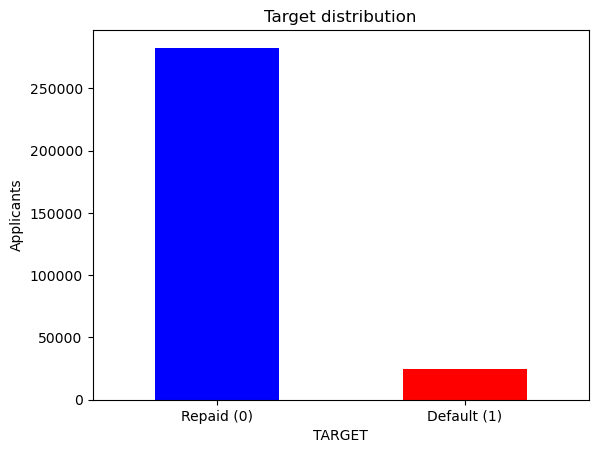

In [26]:
counts = app_train["TARGET"].value_counts()
print(counts)
print(f"Default rate: {app_train['TARGET'].mean():.2%}")

counts.plot(kind="bar", color=["blue", "red"])
plt.xticks([0, 1], ["Repaid (0)", "Default (1)"], rotation=0)
plt.ylabel("Applicants")
plt.title("Target distribution")
plt.show()

The target is heavily imbalanced: 24,825 applicants (8.07%) defaulted, against 282,686 who repaid meaning that a model that predicted "repaid" for every applicant would achieve around 92% accuracy while identifying no defaulters, so accuracy is not a meaningful metric here. Models are instead evaluated using ROC-AUC, PR-AUC, precision and recall to address this imbalance while training.

#

## 5. Key Features vs Default

### 5.1 Correlation with Target

Numeric features are ranked by their Pearson correlation with `TARGET`. Correlation only captures linear relationships and excludes categorical features, so it is used here as an initial screen. Feature importance is assessed more fully with SHAP in notebook 03.

In [27]:
corr = app_train.select_dtypes("number").drop(columns="SK_ID_CURR").corr()["TARGET"].drop("TARGET").sort_values()
pd.concat([corr.head(10), corr.tail(10)]).to_frame("corr_with_target")

,corr_with_target
EXT_SOURCE_3,-0.18
EXT_SOURCE_2,-0.16
EXT_SOURCE_1,-0.16
DAYS_EMPLOYED,-0.04
FLOORSMAX_AVG,-0.04
FLOORSMAX_MEDI,-0.04
FLOORSMAX_MODE,-0.04
AMT_GOODS_PRICE,-0.04
REGION_POPULATION_RELATIVE,-0.04
ELEVATORS_AVG,-0.03


The external source scores stand out as the strongest predictors, each with a correlation of around -0.17: applicants with higher scores are less likely to default.  
Age is next. `DAYS_BIRTH` is stored as negative days, so its positive correlation (0.08) means younger applicants default more often. 

# 

### Summary

All seven tables have complete and unique primary keys. The only repeated keys, in `installments`, were confirmed as partial payments. The main data quality issues are placeholder values (365,243 in `DAYS_` fields, and `XNA` and `Unknown` in categorical fields), a small number of near-constant and sparse fields, and isolated implausible or extreme values. The treatment of each is set out in section 3.4 and applied in notebook 02.

The target is heavily imbalanced, with 8.07% of applicants defaulting, so accuracy is not used as an evaluation metric. The external source scores are the strongest individual predictors of default, followed by age. All correlations with the target are weak, which suggests that the models will need to combine many features rather than rely on a single strong one.

# 

## 8. Save

The raw tables are saved in parquet format so that notebooks 02 and 03 can load them faster. No changes have been made to the data in this notebook.

In [28]:
app_train.to_parquet(directory / "application_train.parquet")
bureau.to_parquet(directory / "bureau.parquet")
bureau_balance.to_parquet(directory / "bureau_balance.parquet")
prev_app.to_parquet(directory / "previous_application.parquet")
pos_cash.to_parquet(directory / "POS_CASH_balance.parquet")
credit_card.to_parquet(directory / "credit_card_balance.parquet")
installments.to_parquet(directory / "installments_payments.parquet")